SAMPLE DELIVERY DATA
   distance_km  warehouse_processing_hours  traffic_level  weather_delay  \
0   377.667418                    9.701248              4              0   
1   950.960735                   26.469345              3              0   
2   733.333972                   42.028454              4              0   
3   600.665192                   35.414570              2              0   
4   160.238547                   38.908374              2              0   

   delivery_partner_rating  order_day  delivery_delayed  
0                 2.746843          5                 0  
1                 2.689153          6                 1  
2                 3.403853          3                 1  
3                 2.730420          4                 1  
4                 3.962696          6                 0  

DATASET SHAPE: (1000, 7)

DELIVERY OUTCOME COUNTS
delivery_delayed
On Time    534
Delayed    466
Name: count, dtype: int64

MODEL PERFORMANCE
Accuracy: 0.66
ROC-AUC: 0.712



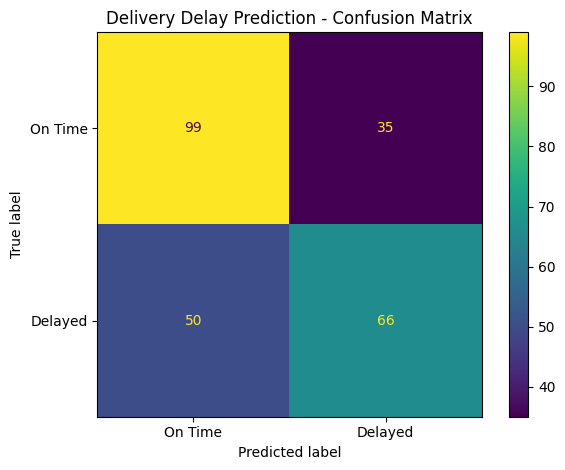


FEATURE IMPORTANCE
                   Feature  Importance
               distance_km    0.280925
warehouse_processing_hours    0.246298
   delivery_partner_rating    0.242649
             traffic_level    0.106451
                 order_day    0.095314
             weather_delay    0.028363


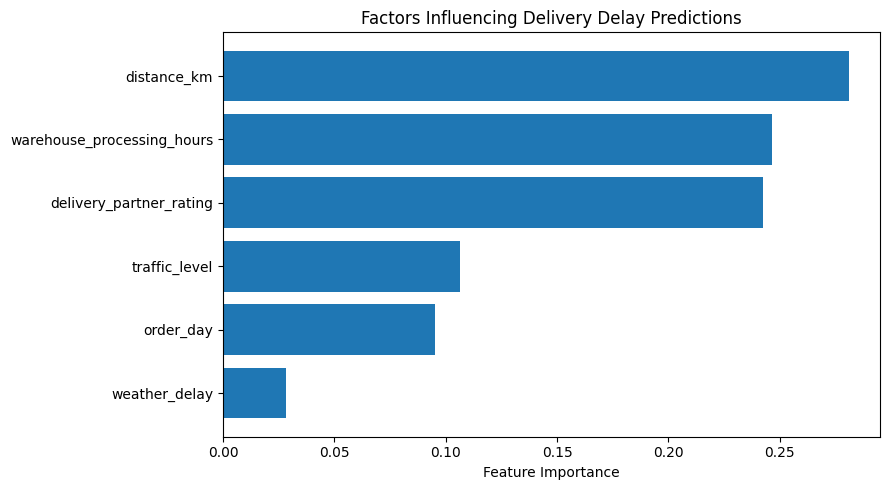


DELIVERY RISK SUMMARY
risk_category
Low       482
High      400
Medium    118
Name: count, dtype: int64

Simulated overall delay rate: 46.6 %

TOP 15 DELIVERIES BY PREDICTED DELAY RISK
 distance_km  warehouse_processing_hours  traffic_level  weather_delay  delivery_partner_rating  delivery_delayed  delay_risk risk_category                                 recommended_action
     896.611                      45.916              4              0                    3.186                 1       1.000          High Prioritize shipment and investigate possible delay
     522.563                      45.716              4              0                    2.818                 1       0.987          High Prioritize shipment and investigate possible delay
     659.325                      45.691              4              1                    3.366                 1       0.980          High Prioritize shipment and investigate possible delay
     644.207                      42.051          

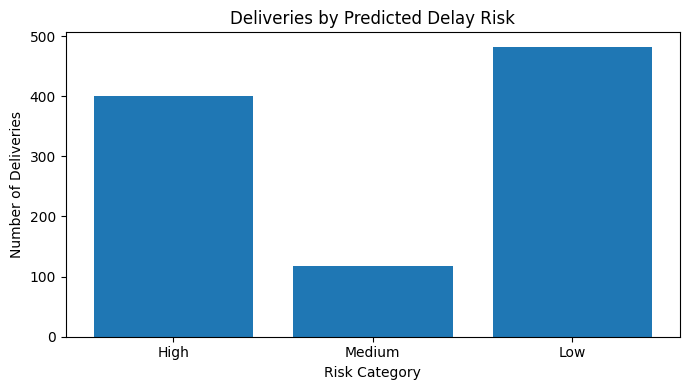


BUSINESS RECOMMENDATIONS
1. Prioritize shipments with high predicted delay risk.
2. Review warehouse processing bottlenecks.
3. Monitor traffic and adverse weather conditions.
4. Track delivery partner performance.
5. Use actual delivery records to validate the model.

DISCLAIMER
This project uses synthetic data and simulated delay outcomes.
The model is an educational prototype, not a validated operational system.


In [1]:

# PROJECT 11: DELIVERY PERFORMANCE CRISIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# 1. Generate sample delivery data
np.random.seed(42)
n = 1000

df = pd.DataFrame({
    "distance_km": np.random.uniform(5, 1000, n),
    "warehouse_processing_hours": np.random.uniform(1, 48, n),
    "traffic_level": np.random.randint(1, 6, n),
    "weather_delay": np.random.binomial(1, 0.20, n),
    "delivery_partner_rating": np.random.uniform(2.5, 5.0, n),
    "order_day": np.random.randint(1, 8, n)
})

# 2. Simulate whether an order is delayed
delay_score = (
    -3.0
    + 0.002 * df["distance_km"]
    + 0.035 * df["warehouse_processing_hours"]
    + 0.40 * (df["traffic_level"] - 1)
    + 1.0 * df["weather_delay"]
    - 0.60 * (df["delivery_partner_rating"] - 3.5)
    + 0.15 * (df["order_day"] == 7).astype(int)
)

delay_probability = 1 / (1 + np.exp(-delay_score))

df["delivery_delayed"] = (
    np.random.random(n) < delay_probability
).astype(int)

# 3. Explore delivery performance
print("SAMPLE DELIVERY DATA")
print(df.head())

print("\nDATASET SHAPE:", df.shape)

print("\nDELIVERY OUTCOME COUNTS")
print(
    df["delivery_delayed"]
    .map({0: "On Time", 1: "Delayed"})
    .value_counts()
)

# 4. Prepare training and testing datasets
X = df.drop(columns=["delivery_delayed"])
y = df["delivery_delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 5. Train a Random Forest classification model
model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# 6. Evaluate model performance
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        predictions,
        target_names=["On Time", "Delayed"],
        zero_division=0
    )
)

# 7. Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["On Time", "Delayed"],
    values_format="d"
)
plt.title("Delivery Delay Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. Identify factors associated with model predictions
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Factors Influencing Delivery Delay Predictions")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

# 9. Calculate predicted delay risk for each delivery
df["delay_risk"] = model.predict_proba(X)[:, 1]

def classify_delay_risk(score):
    if score >= 0.65:
        return "High"
    elif score >= 0.35:
        return "Medium"
    return "Low"

df["risk_category"] = df["delay_risk"].apply(
    classify_delay_risk
)

def recommend_action(category):
    if category == "High":
        return "Prioritize shipment and investigate possible delay"
    elif category == "Medium":
        return "Monitor shipment progress and confirm dispatch"
    return "Continue routine delivery tracking"

df["recommended_action"] = df["risk_category"].apply(
    recommend_action
)

# 10. Summarize delivery performance
print("\nDELIVERY RISK SUMMARY")
print(df["risk_category"].value_counts())

actual_delay_rate = df["delivery_delayed"].mean() * 100

print(
    "\nSimulated overall delay rate:",
    round(actual_delay_rate, 2),
    "%"
)

# 11. Show highest-risk deliveries
print("\nTOP 15 DELIVERIES BY PREDICTED DELAY RISK")

print(
    df.sort_values("delay_risk", ascending=False)[
        [
            "distance_km",
            "warehouse_processing_hours",
            "traffic_level",
            "weather_delay",
            "delivery_partner_rating",
            "delivery_delayed",
            "delay_risk",
            "risk_category",
            "recommended_action"
        ]
    ].head(15).round(3).to_string(index=False)
)

# 12. Visualize risk categories
risk_counts = df["risk_category"].value_counts().reindex(
    ["High", "Medium", "Low"],
    fill_value=0
)

plt.figure(figsize=(7, 4))
plt.bar(risk_counts.index, risk_counts.values)
plt.title("Deliveries by Predicted Delay Risk")
plt.xlabel("Risk Category")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

# 13. Business recommendations
print("\nBUSINESS RECOMMENDATIONS")
print("1. Prioritize shipments with high predicted delay risk.")
print("2. Review warehouse processing bottlenecks.")
print("3. Monitor traffic and adverse weather conditions.")
print("4. Track delivery partner performance.")
print("5. Use actual delivery records to validate the model.")

print("\nDISCLAIMER")
print("This project uses synthetic data and simulated delay outcomes.")
print("The model is an educational prototype, not a validated operational system.")
